# Biomarker comparison

This notebook compares the biomarkers selected by three models (XGBoost, Logistic Regression, KNN)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_venn import venn3
from pathlib import Path

In [14]:
knn = pd.read_csv("Results/biomarkers_knn.csv")
logreg = pd.read_csv("Results/biomarkers_logreg.csv")
xgb = pd.read_csv("Results/biomarkers_xgb.csv")

sets_features = {'KNN': set(knn.feature), 'LogReg': set(logreg.feature), 'XGBoost': set(xgb.feature)}
sets_cluster = {'KNN': set(knn.cluster), 'LogReg': set(logreg.cluster), 'XGBoost': set(xgb.cluster)}

## 1. How many biomarkers are shared? (Venn diagrams)

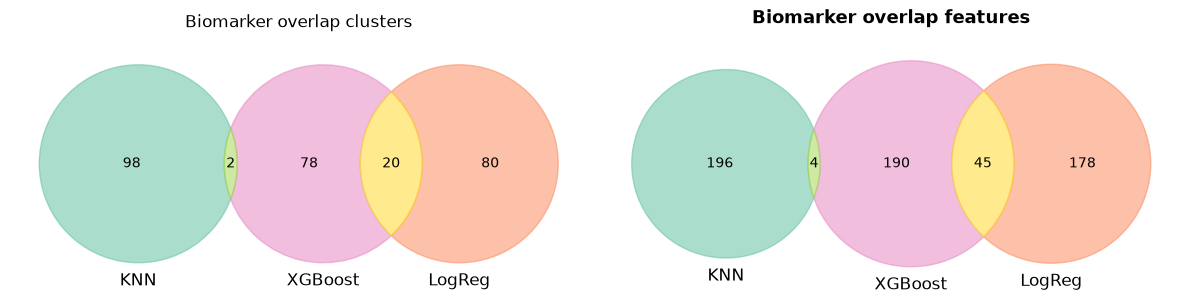

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

v1 = venn3(list(sets_cluster.values()), set_labels
           =list(sets_cluster.keys()), alpha=0.55, ax=axes[0])
axes[0].set_title("Biomarker overlap clusters")


v2 = venn3(list(sets_features.values()), set_labels=list(sets_features.keys()), alpha=0.55, ax=axes[1])
axes[1].set_title("Biomarker overlap features", fontsize=13, weight='bold')

cmap = plt.get_cmap("Set2")
regions = ["100", "010", "110", "001", "101", "011", "111"]

for i, region in enumerate(regions):
    patch1 = v1.get_patch_by_id(region)
    patch2 = v2.get_patch_by_id(region)
    if patch1:
        patch1.set_color(cmap(i % cmap.N))
    if patch2:
        patch2.set_color(cmap(i % cmap.N))

plt.tight_layout()
plt.show()

In [29]:
A, B, X = sets_features.values()
print('Loci shared by all three :', sorted(A & B & X))
print('DT ∩ LogReg              :', sorted(A & B))
print('DT ∩ XGBoost             :', sorted(A & X))
print('LogReg ∩ XGBoost         :', sorted(B & X))

Loci shared by all three : []
DT ∩ LogReg              : []
DT ∩ XGBoost             : ['cnv_depth__IBNLCO_00662__Endoribonuclease__CDS__promoter', 'cnv_depth__IBNLCO_00662__ybeY__gene__promoter', 'cnv_depth__IBNLCO_04998__bprC__gene', 'cnv_depth__IBNLCO_04998__two-component__CDS']
LogReg ∩ XGBoost         : ['cnv_depth__IBNLCO_00312__Avidin__CDS__promoter', 'cnv_depth__IBNLCO_00312__IBNLCO_00312__gene__promoter', 'cnv_depth__IBNLCO_00792__bpeB__gene__promoter', 'cnv_depth__IBNLCO_00792__efflux__CDS__promoter', 'cnv_depth__IBNLCO_00829__Peptide__CDS__promoter', 'cnv_depth__IBNLCO_00829__msrA__gene__promoter', 'cnv_depth__IBNLCO_01157__trnL__gene__promoter', 'cnv_depth__IBNLCO_02542__IBNLCO_02542__gene__promoter', 'cnv_depth__IBNLCO_02542__Thioredoxin__CDS__promoter', 'cnv_depth__IBNLCO_02800__IBNLCO_02800__gene__promoter', 'cnv_depth__IBNLCO_02800__Phosphoribosylformylglycinamidine__CDS__promoter', 'cnv_depth__IBNLCO_02801__DnaA__CDS__promoter', 'cnv_depth__IBNLCO_02801__dnaA__gene__pr

## 2. XGBoost importance: how concentrated is it, and where do DT/LogReg markers fall?

In [ ]:
imp = xgb_sel['importance'].values
cum = np.cumsum(imp) / imp.sum()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.plot(xgb_sel['rank'], imp, color='grey', lw=1)
for name, df in [('Decision tree', dt), ('LogReg', lr)]:
    hit = xgb_sel[xgb_sel.feature.isin(df.feature)]
    ax.scatter(hit['rank'], hit['importance'], s=45, color=COLORS[name], label=name, zorder=3, edgecolor='white')
ax.set_yscale('log'); ax.set_xlabel('XGBoost rank'); ax.set_ylabel('importance (log)')
ax.set_title('XGBoost importance by rank (non-zero only)'); ax.legend()

ax = axes[1]
ax.plot(np.arange(1, len(cum) + 1), cum, color=COLORS['XGBoost'], lw=2)
for q in (0.5, 0.8, 0.95):
    n = int(np.searchsorted(cum, q) + 1)
    ax.axhline(q, ls=':', color='grey'); ax.annotate(f'{int(q*100)}% in top {n}', (n, q), xytext=(5, -12), textcoords='offset points')
ax.set_xlabel('top-N features'); ax.set_ylabel('cumulative share of importance')
ax.set_title('Cumulative XGBoost importance')
plt.tight_layout(); plt.show()
print(f'{(xgb.importance > 0).sum()} of {len(xgb)} features have non-zero importance.')

### Top 30 XGBoost features, coloured by whether DT / LogReg also picked the locus

In [ ]:
top = xgb.head(30).copy()
def who(locus):
    tags = [n for n in ('Decision tree', 'LogReg') if locus in sets_locus[n]]
    return ' + '.join(tags) if tags else 'XGBoost only'
top['also_in'] = top['locus'].apply(who)
pal = {'XGBoost only': '#B0B0B0', 'Decision tree': COLORS['Decision tree'],
       'LogReg': COLORS['LogReg'], 'Decision tree + LogReg': '#8172B3'}
top['label'] = top['locus'] + '  ' + top['annotation'] + ' (' + top['level'] + ')'

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(top['label'][::-1], top['importance'][::-1], color=top['also_in'][::-1].map(pal))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in pal.items() if k in set(top['also_in'])], loc='lower right'); ax.set_xlabel('XGBoost importance')
ax.set_title('Top 30 XGBoost biomarkers'); plt.tight_layout(); plt.show()

## 3. Robustness of the overlap to the XGBoost cut-off
Instead of one threshold, count how many DT / LogReg loci appear in XGBoost's top-N loci as N grows.

In [ ]:
xgb_loci_ranked = xgb.drop_duplicates('locus')['locus'].tolist()   # loci ordered by best feature
Ns = np.arange(1, 301)
fig, ax = plt.subplots(figsize=(9, 4.5))
for name in ('Decision tree', 'LogReg'):
    s = sets_locus[name]
    hits = [len(s & set(xgb_loci_ranked[:n])) for n in Ns]
    ax.step(Ns, hits, where='post', color=COLORS[name], lw=2, label=f'{name} ({len(s)} loci)')
ax.axvline(len(sets_locus['XGBoost']), ls='--', color='grey')
ax.text(len(sets_locus['XGBoost']) + 5, 0.5, 'non-zero importance\ncut-off', color='grey')
ax.set_xlabel('XGBoost top-N loci'); ax.set_ylabel('loci also selected')
ax.set_title('Overlap with XGBoost as a function of N'); ax.legend(); plt.tight_layout(); plt.show()

## 4. What kind of features does each model pick?
Gene vs CDS feature, and whether the promoter region is included.

In [ ]:
comp = pd.concat([
    dt.assign(model='Decision tree'), lr.assign(model='LogReg'),
    xgb_sel.assign(model='XGBoost'), xgb.assign(model='All features (background)')], ignore_index=True)
comp['type'] = comp['level'] + np.where(comp['promoter'], ' + promoter', '')
tab = pd.crosstab(comp['model'], comp['type'], normalize='index').loc[
    ['All features (background)', 'Decision tree', 'LogReg', 'XGBoost']]
ax = tab.plot(kind='barh', stacked=True, figsize=(9, 3.8), colormap='tab20c', width=0.7)
ax.set_xlabel('share of selected features'); ax.set_ylabel('')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
ax.set_title('Feature type composition'); plt.tight_layout(); plt.show()
tab.round(2)

## 5. Notes
* The `cluster` ids in the DT and LogReg files come from different clusterings (e.g. locus IBNLCO_02855 is cluster 3227 in DT but 3625 in LogReg), so they are not compared directly.
* Change `XGB_MIN_IMPORTANCE` at the top to tighten the XGBoost set (e.g. 0.005) and re-run everything.